# 3D U-Net for Multimodal Brain Tumor Segmentation

The main upgrade is that the model learns from **3D spatial context across neighboring slices**, rather than treating each MRI slice independently.

Classes:
- 0 — Background
- 1 — Necrotic / non-enhancing tumor
- 2 — Edema
- 3 — Enhancing tumor

Primary metrics:
- Whole Tumor Dice / IoU
- Tumor Core Dice / IoU
- Enhancing Tumor Dice / IoU
- Mean Foreground Dice / IoU

## 1. Setup

In [1]:
!pip -q install nibabel scikit-image

import os, re, gc, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Configuration

3D volumes are trained as patches to keep GPU memory practical on Kaggle. Complete test volumes are reconstructed later with overlapping sliding-window inference.

In [3]:
IMG_H, IMG_W, IMG_D = 96, 96, 64
PATCH_SIZE = (IMG_H, IMG_W, IMG_D)

N_CHANNELS = 4
NUM_CLASSES = 4
MODALITIES = ["flair", "t1", "t1ce", "t2"]

BATCH_SIZE = 1
BASE_FILTERS = 32

EPOCHS = 30
STEPS_PER_EPOCH = 160
VAL_STEPS = 40
LEARNING_RATE = 1e-4

TUMOR_PATCH_PROB = 0.75
INFER_STRIDE = (64, 64, 32)

VAL_SIZE = 0.15
TEST_SIZE = 0.15

ARTIFACT_DIR = "/kaggle/working/brain_tumor_3d_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

print("Patch size:", PATCH_SIZE)
print("Batch size:", BATCH_SIZE)
print("Base filters:", BASE_FILTERS)
print("Artifact directory:", ARTIFACT_DIR)

Patch size: (96, 96, 64)
Batch size: 1
Base filters: 32
Artifact directory: /kaggle/working/brain_tumor_3d_artifacts


## 3. Locate BraTS2020

In [4]:
def locate_patient_root():
    roots = [
        "/kaggle/input/brats20-dataset-training-validation",
        "/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation",
        "/kaggle/input/brats20",
        "/kaggle/input",
    ]
    for root in roots:
        if not os.path.exists(root):
            continue
        for current, dirs, _ in os.walk(root):
            if sum(d.startswith("BraTS20_Training_") for d in dirs) >= 5:
                return current
    return None

DATA_DIR = locate_patient_root()
if DATA_DIR is None:
    raise FileNotFoundError(
        "BraTS20_Training_* folders were not found. Attach the BraTS2020 dataset in Kaggle."
    )

patient_dirs = sorted([
    os.path.join(DATA_DIR, d)
    for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
    and d.startswith("BraTS20_Training_")
])

print("DATA_DIR:", DATA_DIR)
print("Patient folders found:", len(patient_dirs))

DATA_DIR: /kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData
Patient folders found: 369


## 4. Map MRI files

In [5]:
def first_matching_file(folder, patterns):
    files = sorted(os.listdir(folder))
    for pat in patterns:
        for f in files:
            if re.search(pat, f, re.I):
                return os.path.join(folder, f)
    return None

def patient_file_map(folder):
    return {
        "flair": first_matching_file(folder, [r"_flair\.nii(\.gz)?$"]),
        "t1": first_matching_file(folder, [r"_t1\.nii(\.gz)?$"]),
        "t1ce": first_matching_file(folder, [r"_t1ce\.nii(\.gz)?$", r"_t1gd\.nii(\.gz)?$"]),
        "t2": first_matching_file(folder, [r"_t2\.nii(\.gz)?$"]),
        "seg": first_matching_file(folder, [r"_seg\.nii(\.gz)?$"]),
    }

records = []
for folder in patient_dirs:
    fmap = patient_file_map(folder)
    if all(fmap[m] is not None for m in MODALITIES + ["seg"]):
        records.append({"patient_id": os.path.basename(folder), "folder": folder, **fmap})

patients = pd.DataFrame(records)
print("Usable patients:", len(patients))
print("Patients excluded:", len(patient_dirs) - len(patients))
display(patients.head())

Usable patients: 368
Patients excluded: 1


,patient_id,folder,flair,t1,t1ce,t2,seg
0,BraTS20_Training_001,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...
1,BraTS20_Training_002,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...
2,BraTS20_Training_003,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...
3,BraTS20_Training_004,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...
4,BraTS20_Training_005,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...,/kaggle/input/datasets/awsaf49/brats20-dataset...


## 5. Patient-level train / validation / test split

The split happens before patch extraction, preventing patches from the same patient from appearing in different sets.

In [6]:
train_df, temp_df = train_test_split(
    patients, test_size=VAL_SIZE + TEST_SIZE, random_state=SEED, shuffle=True
)
relative_test = TEST_SIZE / (VAL_SIZE + TEST_SIZE)

val_df, test_df = train_test_split(
    temp_df, test_size=relative_test, random_state=SEED, shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train patients:", len(train_df))
print("Validation patients:", len(val_df))
print("Test patients:", len(test_df))
print("Train/Val overlap:", len(set(train_df.patient_id) & set(val_df.patient_id)))
print("Train/Test overlap:", len(set(train_df.patient_id) & set(test_df.patient_id)))
print("Val/Test overlap:", len(set(val_df.patient_id) & set(test_df.patient_id)))

Train patients: 257
Validation patients: 55
Test patients: 56
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


## 6. MRI loading and normalization

Each modality is normalized using its non-zero voxels. BraTS label 4 is remapped to class 3.

In [7]:
def load_nifti(path):
    return nib.load(path).get_fdata().astype(np.float32)

def normalize_modality(volume):
    mask = volume != 0
    if not np.any(mask):
        return volume.astype(np.float32)
    values = volume[mask]
    mean, std = values.mean(), values.std()
    if std < 1e-6:
        std = 1.0
    out = np.zeros_like(volume, dtype=np.float32)
    out[mask] = (volume[mask] - mean) / std
    return out

def load_patient(row):
    channels = [normalize_modality(load_nifti(row[m])) for m in MODALITIES]
    image = np.stack(channels, axis=-1).astype(np.float32)

    mask = load_nifti(row["seg"]).astype(np.uint8)
    mask[mask == 4] = 3

    return image, mask

sample_image, sample_mask = load_patient(train_df.iloc[0])
print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Mask labels:", np.unique(sample_mask))

Image shape: (240, 240, 155, 4)
Mask shape: (240, 240, 155)
Mask labels: [0 1 2 3]


## 7. Visualize one patient

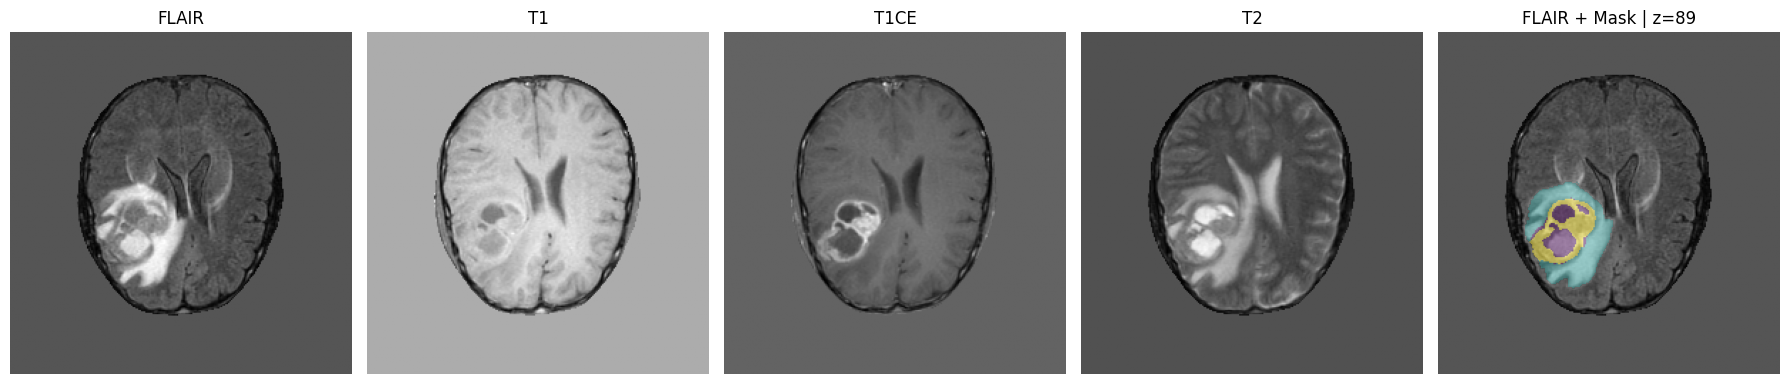

In [8]:
def show_patient_slice(image, mask, z=None):
    if z is None:
        tumor_counts = (mask > 0).sum(axis=(0, 1))
        z = int(np.argmax(tumor_counts))

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    for i, modality in enumerate(MODALITIES):
        axes[i].imshow(image[:, :, z, i].T, cmap="gray", origin="lower")
        axes[i].set_title(modality.upper())
        axes[i].axis("off")

    axes[4].imshow(image[:, :, z, 0].T, cmap="gray", origin="lower")
    axes[4].imshow(
        np.ma.masked_where(mask[:, :, z].T == 0, mask[:, :, z].T),
        alpha=0.45, origin="lower"
    )
    axes[4].set_title(f"FLAIR + Mask | z={z}")
    axes[4].axis("off")
    plt.tight_layout()
    plt.show()

show_patient_slice(sample_image, sample_mask)

## 8. 3D patch sampling

The network receives 96×96×64 volumetric patches. Most training patches are sampled around tumor voxels so the model sees difficult foreground regions frequently, while random patches retain background context.

In [9]:
def random_start(max_start):
    return np.random.randint(0, max_start + 1) if max_start > 0 else 0

def crop_patch(image, mask, start):
    ph, pw, pd = PATCH_SIZE
    z0, y0, x0 = start
    return (
        image[z0:z0+ph, y0:y0+pw, x0:x0+pd],
        mask[z0:z0+ph, y0:y0+pw, x0:x0+pd]
    )

def sample_patch(image, mask, tumor_probability=TUMOR_PATCH_PROB):
    H, W, D = mask.shape
    ph, pw, pd = PATCH_SIZE
    max_z, max_y, max_x = H-ph, W-pw, D-pd

    use_tumor = np.any(mask > 0) and np.random.rand() < tumor_probability

    if use_tumor:
        coords = np.argwhere(mask > 0)
        center = coords[np.random.randint(len(coords))]
        z0 = np.clip(int(center[0] - ph//2), 0, max_z)
        y0 = np.clip(int(center[1] - pw//2), 0, max_y)
        x0 = np.clip(int(center[2] - pd//2), 0, max_x)
    else:
        z0, y0, x0 = random_start(max_z), random_start(max_y), random_start(max_x)

    return crop_patch(image, mask, (z0, y0, x0))

patch_img, patch_mask = sample_patch(sample_image, sample_mask)
print("Patch image:", patch_img.shape)
print("Patch mask:", patch_mask.shape)
print("Patch labels:", np.unique(patch_mask))

Patch image: (96, 96, 64, 4)
Patch mask: (96, 96, 64)
Patch labels: [0 1 2 3]


## 9. 3D augmentation

In [10]:
def augment_3d(image, mask):
    image = np.asarray(image, dtype=np.float32)
    mask = np.asarray(mask, dtype=np.int32)

    # Random flip along height
    if np.random.rand() > 0.5:
        image = np.flip(image, axis=0).copy()
        mask = np.flip(mask, axis=0).copy()

    # Random flip along width
    if np.random.rand() > 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    # Random 90-degree rotation ONLY in the axial plane
    k = np.random.randint(0, 4)
    if k:
        image = np.rot90(image, k=k, axes=(0, 1)).copy()
        mask = np.rot90(mask, k=k, axes=(0, 1)).copy()

    return image, mask

## 10. Patch generator

3D patches are generated on demand instead of storing a large 3D patch dataset in RAM.

In [11]:
class PatchSequence(keras.utils.Sequence):
    def __init__(self, dataframe, steps_per_epoch, augment=False, tumor_probability=0.75):
        self.df = dataframe.reset_index(drop=True)
        self.steps = steps_per_epoch
        self.augment = augment
        self.tumor_probability = tumor_probability

    def __len__(self):
        return self.steps

    def __getitem__(self, index):
        row = self.df.iloc[np.random.randint(len(self.df))]
        image, mask = load_patient(row)

        x, y = sample_patch(
            image, mask,
            tumor_probability=self.tumor_probability if self.augment else 0.50
        )

        if self.augment:
            x, y = augment_3d(x, y)

        x = np.expand_dims(np.asarray(x, dtype=np.float32), 0)
        y = np.expand_dims(np.asarray(y, dtype=np.int32), 0)
        return x, y

train_seq = PatchSequence(train_df, STEPS_PER_EPOCH, augment=True, tumor_probability=TUMOR_PATCH_PROB)
val_seq = PatchSequence(val_df, VAL_STEPS, augment=False, tumor_probability=0.50)

x0, y0 = train_seq[0]
print("Training batch:", x0.shape, y0.shape)
print("Mask labels:", np.unique(y0))

Training batch: (1, 96, 96, 64, 4) (1, 96, 96, 64)
Mask labels: [0 1 2 3]


## 11. 3D U-Net

This is the new Priority-2 baseline.

Encoder: learns local 3D spatial features.

Bottleneck: captures high-level volumetric information.

Decoder + skip connections: recover fine tumor boundaries.

We will use this as the reference model before adding the Transformer/XAI upgrades.

In [15]:
def conv3d_block(x, filters, name):
    x = layers.Conv3D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv3D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)
    return x

def encoder_block(x, filters, name):
    features = conv3d_block(x, filters, name)
    pooled = layers.MaxPooling3D(2, name=f"{name}_pool")(features)
    return features, pooled

def decoder_block(x, skip, filters, name):
    x = layers.Conv3DTranspose(filters, 2, strides=2, padding="same", name=f"{name}_up")(x)
    x = layers.Concatenate(name=f"{name}_concat")([x, skip])
    return conv3d_block(x, filters, name)

def build_3d_unet():
    inp = layers.Input((*PATCH_SIZE, N_CHANNELS), name="mri_3d_input")

    s1, p1 = encoder_block(inp, BASE_FILTERS, "enc1")
    s2, p2 = encoder_block(p1, BASE_FILTERS*2, "enc2")
    s3, p3 = encoder_block(p2, BASE_FILTERS*4, "enc3")

    b = conv3d_block(p3, BASE_FILTERS*8, "bottleneck")

    d3 = decoder_block(b, s3, BASE_FILTERS*4, "dec3")
    d2 = decoder_block(d3, s2, BASE_FILTERS*2, "dec2")
    d1 = decoder_block(d2, s1, BASE_FILTERS, "dec1")

    out = layers.Conv3D(NUM_CLASSES, 1, activation="softmax", name="segmentation_output")(d1)
    return Model(inp, out, name="3D_UNet_BraTS")

model = build_3d_unet()
model.summary()
print("Total parameters:", model.count_params())

Model: "3D_UNet_BraTS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mri_3d_input        │ (None, 96, 96,    │          0 │ -                 │
│ (InputLayer)        │ 64, 4)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv3D) │ (None, 96, 96,    │      3,456 │ mri_3d_input[0][… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_bn1            │ (None, 96, 96,    │        128 │ enc1_conv1[0][0]  │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_relu1          │ (None, 96, 96,    │          0 │ enc1_bn1[0][0]    │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv3D) │ (None, 96, 96,    │     27,648 │ enc1_relu1[0][0]  │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_bn2            │ (None, 96, 96,    │        128 │ enc1_conv2[0][0]  │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_relu2          │ (None, 96, 96,    │          0 │ enc1_bn2[0][0]    │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_pool           │ (None, 48, 48,    │          0 │ enc1_relu2[0][0]  │
│ (MaxPooling3D)      │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv3D) │ (None, 48, 48,    │     55,296 │ enc1_pool[0][0]   │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_bn1            │ (None, 48, 48,    │        256 │ enc2_conv1[0][0]  │
│ (BatchNormalizatio… │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_relu1          │ (None, 48, 48,    │          0 │ enc2_bn1[0][0]    │
│ (Activation)        │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv3D) │ (None, 48, 48,    │    110,592 │ enc2_relu1[0][0]  │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_bn2            │ (None, 48, 48,    │        256 │ enc2_conv2[0][0]  │
│ (BatchNormalizatio… │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_relu2          │ (None, 48, 48,    │          0 │ enc2_bn2[0][0]    │
│ (Activation)        │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_pool           │ (None, 24, 24,    │          0 │ enc2_relu2[0][0]  │
│ (MaxPooling3D)      │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_conv1 (Conv3D) │ (None, 24, 24,    │    221,184 │ enc2_pool[0][0]   │
│                     │ 16, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc3_bn1            │ (None, 24, 24,    │        512 │ enc3_conv1[0][0]

 Total params: 5,606,628 (21.39 MB)

 Trainable params: 5,603,812 (21.38 MB)

 Non-trainable params: 2,816 (11.00 KB)

Total parameters: 5606628


## 12. Loss and metrics

In [16]:
def foreground_dice(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.int32)
    one_hot = tf.one_hot(y_true, NUM_CLASSES)

    inter = tf.reduce_sum(one_hot * y_pred, axis=[1,2,3])
    denom = tf.reduce_sum(one_hot + y_pred, axis=[1,2,3])

    dice = (2.0*inter + smooth) / (denom + smooth)
    return tf.reduce_mean(dice[:, 1:])

def loss_fn(y_true, y_pred):
    ce = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred))
    return ce + (1.0 - foreground_dice(y_true, y_pred))

def mean_iou_foreground(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    y_pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)

    ious = []
    for cls in range(1, NUM_CLASSES):
        gt = tf.equal(y_true, cls)
        pr = tf.equal(y_pred, cls)
        inter = tf.reduce_sum(tf.cast(gt & pr, tf.float32), axis=[1,2,3])
        union = tf.reduce_sum(tf.cast(gt | pr, tf.float32), axis=[1,2,3])
        ious.append((inter + 1e-6)/(union + 1e-6))

    return tf.reduce_mean(tf.stack(ious, axis=0))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=loss_fn,
    metrics=[foreground_dice, mean_iou_foreground]
)

print("Model compiled successfully.")

Model compiled successfully.


## 13. Sanity check

Run this before full training. If this cell succeeds, the input shapes, model, loss and one GPU training step are working.

In [14]:
x_batch, y_batch = train_seq[0]
print("X:", x_batch.shape, x_batch.dtype)
print("Y:", y_batch.shape, y_batch.dtype)

result = model.train_on_batch(x_batch, y_batch, return_dict=True)
print(result)

X: (1, 96, 96, 64, 4) float32
Y: (1, 96, 96, 64) int32


2026-10-01 16:15:52.924759: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng0{} for conv (f32[32,64,3,3,3]{4,3,2,1,0}, u8[0]{0}) custom-call(f32[1,64,96,96,64]{4,3,2,1,0}, f32[1,32,96,96,64]{4,3,2,1,0}), window={size=3x3x3 pad=1_1x1_1x1_1}, dim_labels=bf012_oi012->bf012, custom_call_target="__cudnn$convBackwardFilter", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-01 16:15:53.560637: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.636008801s
Trying algorithm eng0{} for conv (f32[32,64,3,3,3]{4,3,2,1,0}, u8[0]{0}) custom-call(f32[1,64,96,96,64]{4,3,2,1,0}, f32[1,32,96,96,64]{4,3,2,1,0}), window={size=3x3x3 pad=1_1x1_1x1_1}, dim_labels=bf012_oi012->bf012, custom_call_target="__cudnn$convBackwardFi

{'foreground_dice': array(0.09432273, dtype=float32), 'loss': array(2.4401267, dtype=float32), 'mean_iou_foreground': array(0.03709389, dtype=float32)}


## 14. Train

The first run is deliberately conservative. We can adjust patch size, filters, steps, or epochs after seeing GPU memory and learning behavior.

In [17]:
checkpoint_path = os.path.join(ARTIFACT_DIR, "best_3d_unet_model.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_foreground_dice",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_foreground_dice",
        mode="max",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    train_seq,
    validation_data=val_seq,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("Best model:", checkpoint_path)

Epoch 1/30
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - foreground_dice: 0.1210 - loss: 2.0461 - mean_iou_foreground: 0.1724
Epoch 1: val_foreground_dice improved from None to 0.14265, saving model to /kaggle/working/brain_tumor_3d_artifacts/best_3d_unet_model.keras

Epoch 1: finished saving model to /kaggle/working/brain_tumor_3d_artifacts/best_3d_unet_model.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 324s 2s/step - foreground_dice: 0.1516 - loss: 1.7622 - mean_iou_foreground: 0.2455 - val_foreground_dice: 0.1427 - val_loss: 1.6165 - val_mean_iou_foreground: 0.2813 - learning_rate: 1.0000e-04
Epoch 2/30
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - foreground_dice: 0.1747 - loss: 1.4298 - mean_iou_foreground: 0.3264
Epoch 2: val_foreground_dice improved from 0.14265 to 0.15944, saving model to /kaggle/working/brain_tumor_3d_artifacts/best_3d_unet_model.keras

Epoch 2: finished saving model to /kaggle/working/brain_tumor_3d_artifacts/best_3d_unet_model.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step -

## 15. Training curves

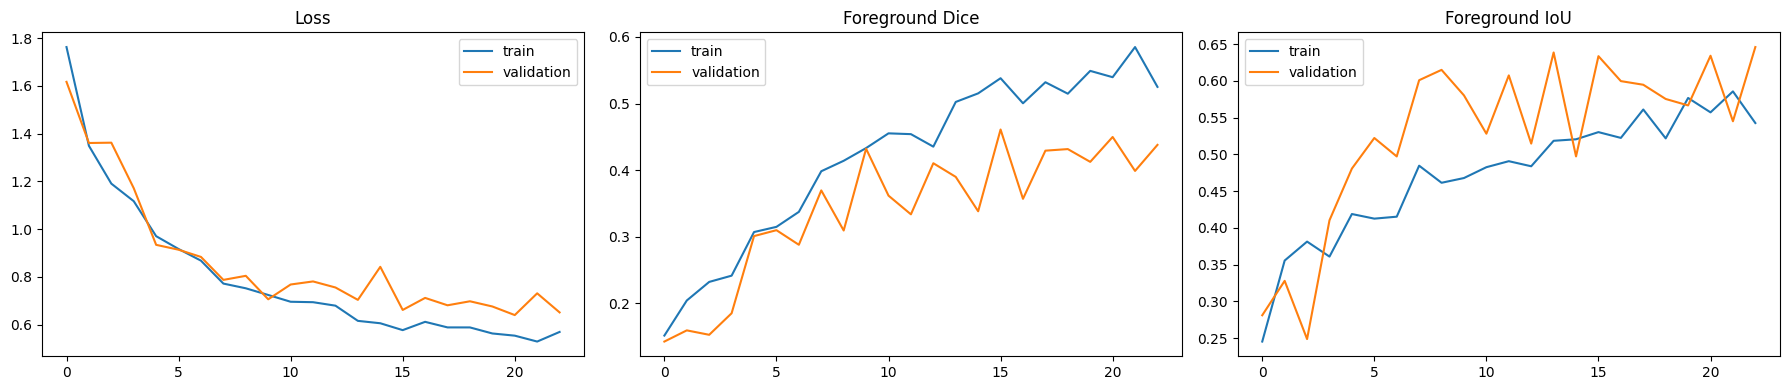

In [18]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(history_df["loss"], label="train")
axes[0].plot(history_df["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(history_df["foreground_dice"], label="train")
axes[1].plot(history_df["val_foreground_dice"], label="validation")
axes[1].set_title("Foreground Dice")
axes[1].legend()

axes[2].plot(history_df["mean_iou_foreground"], label="train")
axes[2].plot(history_df["val_mean_iou_foreground"], label="validation")
axes[2].set_title("Foreground IoU")
axes[2].legend()

plt.tight_layout()
plt.show()

## 16. Load best checkpoint

In [19]:
best_model = keras.models.load_model(
    checkpoint_path,
    custom_objects={
        "foreground_dice": foreground_dice,
        "loss_fn": loss_fn,
        "mean_iou_foreground": mean_iou_foreground,
    },
    compile=False
)

print("Loaded:", checkpoint_path)
print("Parameters:", best_model.count_params())

Loaded: /kaggle/working/brain_tumor_3d_artifacts/best_3d_unet_model.keras
Parameters: 5606628


## 17. Sliding-window inference

The model is trained on 96×96×64 patches, but the test evaluation uses the complete 3D patient volume.

Overlapping patches are averaged to reconstruct a complete probability volume.

In [20]:
def make_starts(length, patch, stride):
    if length <= patch:
        return [0]
    starts = list(range(0, length-patch+1, stride))
    if starts[-1] != length-patch:
        starts.append(length-patch)
    return starts

def sliding_window_predict(model, image, stride=INFER_STRIDE):
    H, W, D, C = image.shape
    ph, pw, pd = PATCH_SIZE

    z_starts = make_starts(H, ph, stride[0])
    y_starts = make_starts(W, pw, stride[1])
    x_starts = make_starts(D, pd, stride[2])

    prob_sum = np.zeros((H,W,D,NUM_CLASSES), dtype=np.float32)
    count = np.zeros((H,W,D,1), dtype=np.float32)

    total = len(z_starts)*len(y_starts)*len(x_starts)
    done = 0

    for z0 in z_starts:
        for y0 in y_starts:
            for x0 in x_starts:
                patch = image[z0:z0+ph, y0:y0+pw, x0:x0+pd, :]
                pred = model.predict(patch[None].astype(np.float32), verbose=0)[0]

                prob_sum[z0:z0+ph, y0:y0+pw, x0:x0+pd, :] += pred
                count[z0:z0+ph, y0:y0+pw, x0:x0+pd, :] += 1.0

                done += 1

    return prob_sum / np.maximum(count, 1.0)

print("Sliding-window inference ready.")

Sliding-window inference ready.


## 18. Complete-volume test evaluation

This is the key evaluation cell. Every test patient is evaluated as a complete 3D volume.

The results are not directly interchangeable with the previous selected-slice evaluation; keep the protocols separate when reporting results.

In [21]:
def dice_iou_binary(gt, pred):
    gt = gt.astype(bool)
    pred = pred.astype(bool)

    inter = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()

    dice = (2.0*inter + 1e-6)/(gt.sum() + pred.sum() + 1e-6)
    iou = (inter + 1e-6)/(union + 1e-6)
    return float(dice), float(iou)

def evaluate_volume(gt, pred):
    result = {}

    for cls, name in [(1,"necrotic"), (2,"edema"), (3,"enhancing")]:
        d, i = dice_iou_binary(gt == cls, pred == cls)
        result[f"{name}_dice"] = d
        result[f"{name}_iou"] = i

    d, i = dice_iou_binary(gt > 0, pred > 0)
    result["whole_tumor_dice"] = d
    result["whole_tumor_iou"] = i

    d, i = dice_iou_binary(np.isin(gt,[1,3]), np.isin(pred,[1,3]))
    result["tumor_core_dice"] = d
    result["tumor_core_iou"] = i

    result["mean_foreground_dice"] = np.mean([
        result["necrotic_dice"], result["edema_dice"], result["enhancing_dice"]
    ])
    result["mean_foreground_iou"] = np.mean([
        result["necrotic_iou"], result["edema_iou"], result["enhancing_iou"]
    ])
    result["pixel_accuracy"] = float(np.mean(gt == pred))
    return result

all_results = []

for idx, row in test_df.iterrows():
    print(f"[{idx+1}/{len(test_df)}] {row['patient_id']}")

    image, gt = load_patient(row)
    probs = sliding_window_predict(best_model, image)
    pred = np.argmax(probs, axis=-1).astype(np.uint8)

    metrics = evaluate_volume(gt, pred)
    metrics["patient_id"] = row["patient_id"]
    all_results.append(metrics)

    del image, gt, probs, pred
    gc.collect()

test_results = pd.DataFrame(all_results)
display(test_results.head())

[1/56] BraTS20_Training_358
[2/56] BraTS20_Training_230
[3/56] BraTS20_Training_058
[4/56] BraTS20_Training_117
[5/56] BraTS20_Training_292
[6/56] BraTS20_Training_247
[7/56] BraTS20_Training_026
[8/56] BraTS20_Training_348
[9/56] BraTS20_Training_141
[10/56] BraTS20_Training_040
[11/56] BraTS20_Training_017
[12/56] BraTS20_Training_067
[13/56] BraTS20_Training_166
[14/56] BraTS20_Training_325
[15/56] BraTS20_Training_333
[16/56] BraTS20_Training_095
[17/56] BraTS20_Training_094
[18/56] BraTS20_Training_310
[19/56] BraTS20_Training_263
[20/56] BraTS20_Training_031
[21/56] BraTS20_Training_153
[22/56] BraTS20_Training_064
[23/56] BraTS20_Training_074
[24/56] BraTS20_Training_238
[25/56] BraTS20_Training_073
[26/56] BraTS20_Training_109
[27/56] BraTS20_Training_057
[28/56] BraTS20_Training_076
[29/56] BraTS20_Training_203
[30/56] BraTS20_Training_110
[31/56] BraTS20_Training_111
[32/56] BraTS20_Training_276
[33/56] BraTS20_Training_127
[34/56] BraTS20_Training_357
[35/56] BraTS20_Trainin

,necrotic_dice,necrotic_iou,edema_dice,edema_iou,enhancing_dice,enhancing_iou,whole_tumor_dice,whole_tumor_iou,tumor_core_dice,tumor_core_iou,mean_foreground_dice,mean_foreground_iou,pixel_accuracy,patient_id
0,3.767606e-01,2.321041e-01,0.933617,0.875499,0.643616,0.474509,0.905602,0.827489,0.602194,0.430813,0.651331,0.527370,0.997757,BraTS20_Training_358
1,1.878724e-01,1.036750e-01,0.941446,0.889369,0.974480,0.950229,0.961219,0.925333,0.920050,0.851938,0.701266,0.647758,0.998940,BraTS20_Training_230
2,9.540164e-11,9.540164e-11,0.587679,0.416109,0.080261,0.041808,0.559269,0.388184,0.032280,0.016405,0.222647,0.152639,0.993030,BraTS20_Training_058
3,7.318031e-01,5.770422e-01,0.929847,0.868892,0.917423,0.847444,0.947861,0.900890,0.927527,0.864848,0.859691,0.764459,0.998841,BraTS20_Training_117
4,6.178311e-01,4.470011e-01,0.322506,0.192255,0.024800,0.012556,0.583188,0.411620,0.592849,0.421312,0.321712,0.217270,0.994469,BraTS20_Training_292


## 19. Aggregate test results

In [22]:
metric_columns = [
    "whole_tumor_dice","whole_tumor_iou",
    "tumor_core_dice","tumor_core_iou",
    "necrotic_dice","necrotic_iou",
    "edema_dice","edema_iou",
    "enhancing_dice","enhancing_iou",
    "mean_foreground_dice","mean_foreground_iou",
    "pixel_accuracy"
]

summary = test_results[metric_columns].mean().to_frame("mean")

print("=== COMPLETE-VOLUME TEST RESULTS ===")
display(summary)

csv_path = os.path.join(ARTIFACT_DIR, "3d_unet_complete_volume_test_metrics.csv")
test_results.to_csv(csv_path, index=False)
print("Saved:", csv_path)

=== COMPLETE-VOLUME TEST RESULTS ===


,mean
whole_tumor_dice,0.829760
whole_tumor_iou,0.728292
tumor_core_dice,0.696069
tumor_core_iou,0.593072
necrotic_dice,0.470383
necrotic_iou,0.360244
edema_dice,0.694502
edema_iou,0.572507
enhancing_dice,0.641072
enhancing_iou,0.544092


Saved: /kaggle/working/brain_tumor_3d_artifacts/3d_unet_complete_volume_test_metrics.csv


## 20. Visualize a test prediction

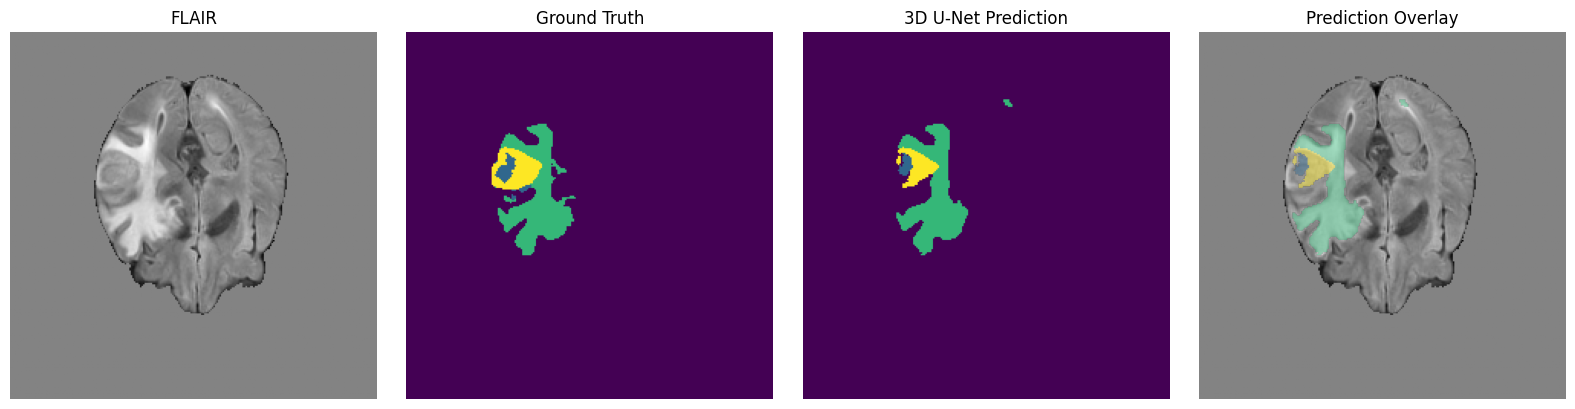

In [23]:
def show_prediction_slice(image, gt, pred, z=None):
    if z is None:
        tumor_counts = (gt > 0).sum(axis=(0,1))
        z = int(np.argmax(tumor_counts))

    fig, axes = plt.subplots(1,4,figsize=(16,4))

    axes[0].imshow(image[:,:,z,0].T,cmap="gray",origin="lower")
    axes[0].set_title("FLAIR")

    axes[1].imshow(gt[:,:,z].T,cmap="viridis",vmin=0,vmax=3,origin="lower")
    axes[1].set_title("Ground Truth")

    axes[2].imshow(pred[:,:,z].T,cmap="viridis",vmin=0,vmax=3,origin="lower")
    axes[2].set_title("3D U-Net Prediction")

    axes[3].imshow(image[:,:,z,0].T,cmap="gray",origin="lower")
    axes[3].imshow(
        np.ma.masked_where(pred[:,:,z].T==0,pred[:,:,z].T),
        alpha=0.45,cmap="viridis",vmin=0,vmax=3,origin="lower"
    )
    axes[3].set_title("Prediction Overlay")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

row = test_df.iloc[0]
test_image, test_gt = load_patient(row)
test_probs = sliding_window_predict(best_model, test_image)
test_pred = np.argmax(test_probs, axis=-1).astype(np.uint8)

show_prediction_slice(test_image, test_gt, test_pred)

# Next stage: Explainability

After this 3D U-Net baseline is working, we will add the explainability layer:

1. 3D Grad-CAM / class-specific activation maps
2. Feature/attention visualization
3. MRI modality ablation analysis
4. Prediction uncertainty estimation
5. Comparison with the previous 2D Attention CNN + ViT

Do not add these until the baseline metrics are recorded. This lets us measure whether each upgrade actually improves the project.

## 21. 3D Grad-CAM Explainability

Grad-CAM is used to visualize the regions that contribute to the model's segmentation prediction.

For this 3D U-Net, the Grad-CAM map is generated from the bottleneck feature representation and calculated separately for each tumor class:

- Class 1 — Necrotic / non-enhancing tumor
- Class 2 — Edema
- Class 3 — Enhancing tumor

The resulting 3D activation map shows which regions of the MRI volume most strongly influence the selected class prediction.

This analysis is performed using the already-trained best 3D U-Net model and does not involve retraining.

In [24]:
# Grad-CAM setup

CLASS_NAMES = {
    0: "Background",
    1: "Necrotic / Non-enhancing",
    2: "Edema",
    3: "Enhancing Tumor"
}

# The final activation layer of the bottleneck block.
GRAD_CAM_LAYER = "bottleneck_relu2"

layer_names = [layer.name for layer in best_model.layers]

if GRAD_CAM_LAYER not in layer_names:
    print("Available bottleneck-related layers:")
    print([name for name in layer_names if "bottleneck" in name.lower()])
    raise ValueError(
        f"{GRAD_CAM_LAYER} was not found. "
        "Use one of the bottleneck activation layers listed above."
    )

print("Grad-CAM layer:", GRAD_CAM_LAYER)
print("Model parameters:", best_model.count_params())

Grad-CAM layer: bottleneck_relu2
Model parameters: 5606628


In [25]:
# 3D Grad-CAM function

def make_3d_gradcam(model, patch, class_index, layer_name=GRAD_CAM_LAYER):
    """
    Generate a class-specific 3D Grad-CAM for one input patch.

    patch shape:
        (H, W, D, 4)

    Returns:
        heatmap with shape (H, W, D), normalized to [0, 1].
    """

    grad_model = keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(layer_name).output,
            model.output
        ]
    )

    input_tensor = tf.convert_to_tensor(
        patch[None].astype(np.float32)
    )

    with tf.GradientTape() as tape:
        activations, predictions = grad_model(input_tensor)

        # Mean probability of the selected class over the 3D patch.
        class_score = tf.reduce_mean(
            predictions[..., class_index]
        )

    gradients = tape.gradient(class_score, activations)

    if gradients is None:
        raise RuntimeError("Gradients could not be computed.")

    # Average gradients over the 3 spatial dimensions.
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2, 3)
    )

    activations = activations[0]
    weights = weights[0]

    # Weighted sum of feature channels.
    heatmap = tf.reduce_sum(
        activations * weights[None, None, None, :],
        axis=-1
    )

    # Keep only positive contributions.
    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap.numpy()

    # Resize bottleneck-resolution map back to input-patch resolution.
    heatmap = tf.image.resize(
        heatmap[..., None],
        patch.shape[:2]
    ).numpy()[..., 0]

    # Resize depth dimension separately.
    if heatmap.shape[2] != patch.shape[2]:
        heatmap = np.stack([
            tf.image.resize(
                heatmap[:, :, z][..., None],
                patch.shape[:2]
            ).numpy()[..., 0]
            for z in range(heatmap.shape[2])
        ], axis=2)

    max_value = np.max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    return heatmap.astype(np.float32)


print("3D Grad-CAM function ready.")

3D Grad-CAM function ready.


In [26]:
# Prepare a deterministic tumor-centered test patch

def extract_tumor_center_patch(image, mask):
    ph, pw, pd = PATCH_SIZE

    H, W, D = mask.shape

    max_z = max(H - ph, 0)
    max_y = max(W - pw, 0)
    max_x = max(D - pd, 0)

    tumor_coords = np.argwhere(mask > 0)

    if len(tumor_coords) == 0:
        center = np.array([
            H // 2,
            W // 2,
            D // 2
        ])
    else:
        center = np.median(tumor_coords, axis=0).astype(int)

    z0 = np.clip(center[0] - ph // 2, 0, max_z)
    y0 = np.clip(center[1] - pw // 2, 0, max_y)
    x0 = np.clip(center[2] - pd // 2, 0, max_x)

    patch_image = image[
        z0:z0+ph,
        y0:y0+pw,
        x0:x0+pd,
        :
    ]

    patch_mask = mask[
        z0:z0+ph,
        y0:y0+pw,
        x0:x0+pd
    ]

    return patch_image, patch_mask


gradcam_patch, gradcam_gt = extract_tumor_center_patch(
    test_image,
    test_gt
)

gradcam_probs = best_model.predict(
    gradcam_patch[None].astype(np.float32),
    verbose=0
)[0]

gradcam_pred = np.argmax(
    gradcam_probs,
    axis=-1
).astype(np.uint8)

print("Grad-CAM patch:", gradcam_patch.shape)
print("Ground truth:", gradcam_gt.shape)
print("Prediction:", gradcam_pred.shape)
print("Labels:", np.unique(gradcam_pred))

Grad-CAM patch: (96, 96, 64, 4)
Ground truth: (96, 96, 64)
Prediction: (96, 96, 64)
Labels: [0 1 2 3]


Generated Grad-CAM maps:
Necrotic / Non-enhancing -> (96, 96, 96) range: 0.000 - 1.000
Edema -> (96, 96, 96) range: 0.000 - 1.000
Enhancing Tumor -> (96, 96, 96) range: 0.000 - 1.000


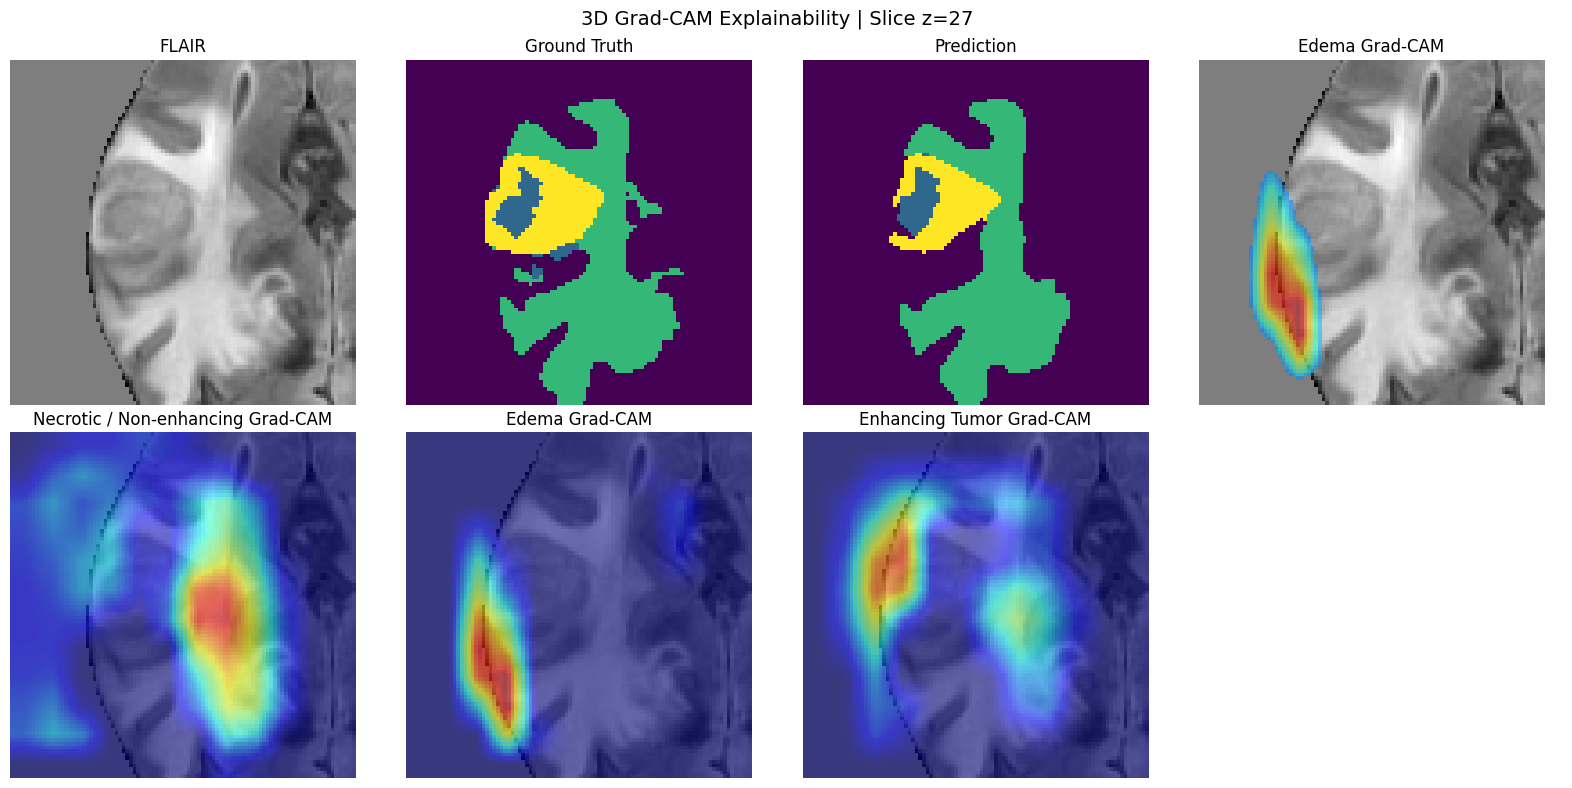

Saved: /kaggle/working/brain_tumor_3d_artifacts/3d_gradcam_visualization.png


In [27]:
# Generate and visualize class-specific 3D Grad-CAM maps

gradcam_maps = {}

for class_index in [1, 2, 3]:
    gradcam_maps[class_index] = make_3d_gradcam(
        best_model,
        gradcam_patch,
        class_index
    )

print("Generated Grad-CAM maps:")
for cls, cam in gradcam_maps.items():
    print(
        CLASS_NAMES[cls],
        "->",
        cam.shape,
        "range:",
        f"{cam.min():.3f} - {cam.max():.3f}"
    )


# Select the slice containing the largest amount of ground-truth tumor.
tumor_counts = (gradcam_gt > 0).sum(axis=(0, 1))
z = int(np.argmax(tumor_counts))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# Original FLAIR
axes[0, 0].imshow(
    gradcam_patch[:, :, z, 0].T,
    cmap="gray",
    origin="lower"
)
axes[0, 0].set_title("FLAIR")

# Ground truth
axes[0, 1].imshow(
    gradcam_gt[:, :, z].T,
    cmap="viridis",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[0, 1].set_title("Ground Truth")

# Prediction
axes[0, 2].imshow(
    gradcam_pred[:, :, z].T,
    cmap="viridis",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[0, 2].set_title("Prediction")

# Whole tumor Grad-CAM
axes[0, 3].imshow(
    gradcam_patch[:, :, z, 0].T,
    cmap="gray",
    origin="lower"
)
axes[0, 3].imshow(
    np.ma.masked_where(
        gradcam_maps[2][:, :, z].T < 0.25,
        gradcam_maps[2][:, :, z].T
    ),
    cmap="jet",
    alpha=0.55,
    vmin=0,
    vmax=1,
    origin="lower"
)
axes[0, 3].set_title("Edema Grad-CAM")

for i, class_index in enumerate([1, 2, 3]):
    axes[1, i].imshow(
        gradcam_patch[:, :, z, 0].T,
        cmap="gray",
        origin="lower"
    )
    axes[1, i].imshow(
        gradcam_maps[class_index][:, :, z].T,
        cmap="jet",
        alpha=0.55,
        vmin=0,
        vmax=1,
        origin="lower"
    )
    axes[1, i].set_title(
        f"{CLASS_NAMES[class_index]} Grad-CAM"
    )

axes[1, 3].axis("off")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    f"3D Grad-CAM Explainability | Slice z={z}",
    fontsize=14
)
plt.tight_layout()

gradcam_path = os.path.join(
    ARTIFACT_DIR,
    "3d_gradcam_visualization.png"
)

plt.savefig(
    gradcam_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", gradcam_path)

## 22. Bottleneck Feature Visualization

The bottleneck is the deepest representation of the 3D U-Net.

At this stage, the network has compressed the input volume into high-level 3D feature maps before the decoder reconstructs the segmentation.

Visualizing these feature maps helps inspect what spatial patterns are represented internally.

This is a feature visualization and should not be interpreted as a medically validated explanation.

In [28]:
# Extract bottleneck features from the Grad-CAM test patch

feature_model = keras.models.Model(
    inputs=best_model.inputs,
    outputs=best_model.get_layer(
        GRAD_CAM_LAYER
    ).output
)

bottleneck_features = feature_model.predict(
    gradcam_patch[None].astype(np.float32),
    verbose=0
)[0]

print("Bottleneck feature shape:", bottleneck_features.shape)
print("Number of feature channels:", bottleneck_features.shape[-1])

Bottleneck feature shape: (12, 12, 8, 256)
Number of feature channels: 256


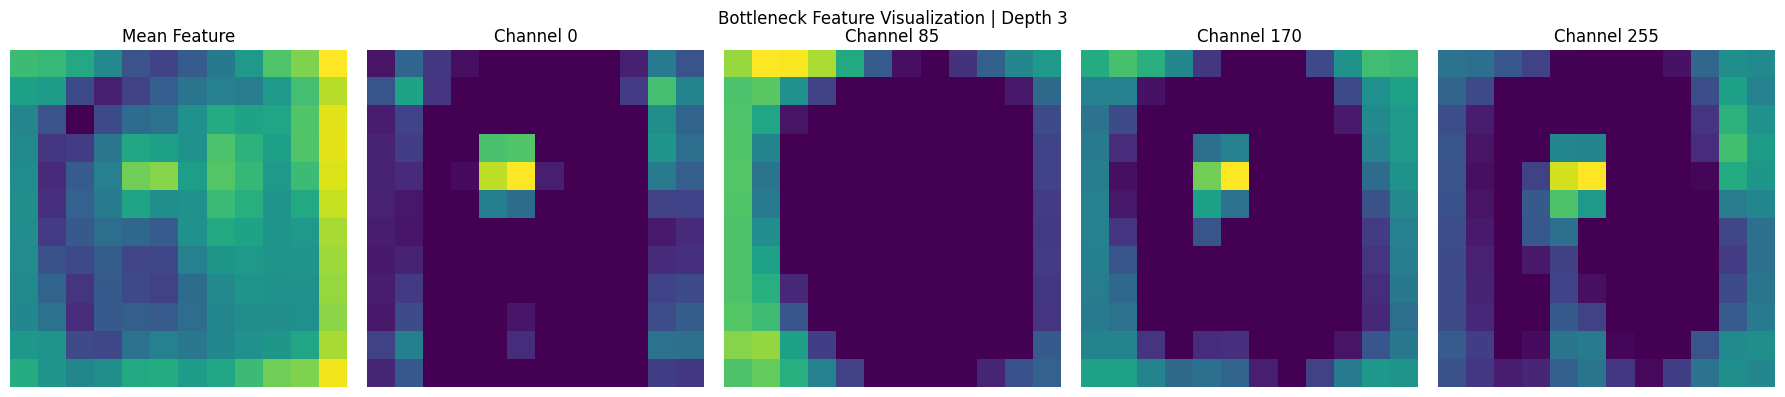

Saved: /kaggle/working/brain_tumor_3d_artifacts/bottleneck_feature_visualization.png


In [29]:
# Visualize representative bottleneck feature maps

# Average activation across channels.
mean_feature = np.mean(
    bottleneck_features,
    axis=-1
)

# Normalize for visualization.
mean_feature = (
    mean_feature - mean_feature.min()
) / (
    mean_feature.max() - mean_feature.min() + 1e-8
)

# Select the depth position corresponding approximately
# to the tumor-containing slice.
feature_z = int(
    np.clip(
        round(
            z * bottleneck_features.shape[2]
            / gradcam_patch.shape[2]
        ),
        0,
        bottleneck_features.shape[2] - 1
    )
)

# Choose a few representative channels.
num_channels = bottleneck_features.shape[-1]
channel_indices = np.linspace(
    0,
    num_channels - 1,
    4,
    dtype=int
)

fig, axes = plt.subplots(
    1, 5,
    figsize=(18, 4)
)

axes[0].imshow(
    mean_feature[:, :, feature_z].T,
    cmap="viridis",
    origin="lower"
)
axes[0].set_title("Mean Feature")

for ax, channel in zip(
    axes[1:],
    channel_indices
):
    feature_map = bottleneck_features[
        :, :, feature_z, channel
    ]

    ax.imshow(
        feature_map.T,
        cmap="viridis",
        origin="lower"
    )
    ax.set_title(f"Channel {channel}")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Bottleneck Feature Visualization | Depth {feature_z}"
)

plt.tight_layout()

feature_path = os.path.join(
    ARTIFACT_DIR,
    "bottleneck_feature_visualization.png"
)

plt.savefig(
    feature_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", feature_path)

## 23. MRI Modality Ablation Analysis

The model uses four MRI modalities:

- FLAIR
- T1
- T1CE
- T2

A modality ablation experiment evaluates how segmentation changes when one modality is removed from the input.

For each ablation, the selected modality is replaced by zero-valued normalized input.

The trained model is not retrained. This isolates the effect of removing modality information during inference.

The primary comparison metric is Whole Tumor Dice.

In [30]:
# Modality ablation utilities

MODALITY_NAMES = ["FLAIR", "T1", "T1CE", "T2"]

# To control runtime, the experiment defaults to 12 held-out test patients.
# Set this to len(test_df) for all 56 test patients.
ABLATION_PATIENTS = min(12, len(test_df))

print(
    f"Modality ablation will use {ABLATION_PATIENTS} "
    f"of {len(test_df)} test patients."
)


def ablate_modality(image, modality_index):
    """
    Return a copy of the MRI volume with one modality removed.

    Since the modalities were normalized, zero corresponds
    approximately to the normalized mean intensity.
    """
    ablated = image.copy().astype(np.float32)
    ablated[..., modality_index] = 0.0
    return ablated


def calculate_whole_tumor_metrics(gt, pred):
    dice, iou = dice_iou_binary(
        gt > 0,
        pred > 0
    )

    return {
        "whole_tumor_dice": dice,
        "whole_tumor_iou": iou
    }


def run_modality_ablation_patient(row):
    image, gt = load_patient(row)

    results = {}

    # Baseline
    baseline_probs = sliding_window_predict(
        best_model,
        image
    )

    baseline_pred = np.argmax(
        baseline_probs,
        axis=-1
    ).astype(np.uint8)

    results["All modalities"] = calculate_whole_tumor_metrics(
        gt,
        baseline_pred
    )

    # Remove one modality at a time.
    for modality_index, modality_name in enumerate(MODALITY_NAMES):

        ablated_image = ablate_modality(
            image,
            modality_index
        )

        probs = sliding_window_predict(
            best_model,
            ablated_image
        )

        pred = np.argmax(
            probs,
            axis=-1
        ).astype(np.uint8)

        results[f"Without {modality_name}"] = (
            calculate_whole_tumor_metrics(
                gt,
                pred
            )
        )

    return results


print("Modality ablation functions ready.")

Modality ablation will use 12 of 56 test patients.
Modality ablation functions ready.


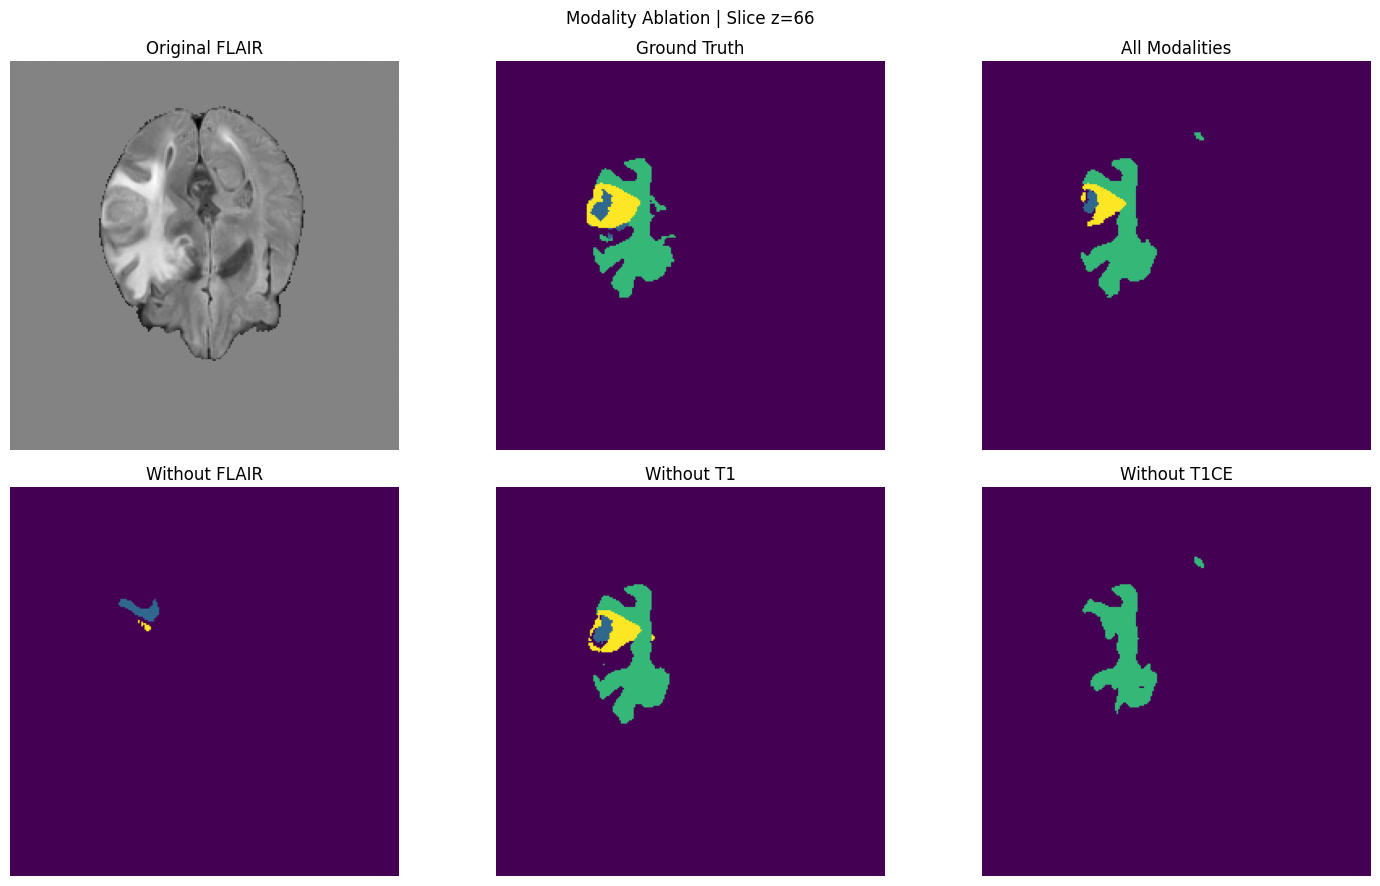

Saved: /kaggle/working/brain_tumor_3d_artifacts/modality_ablation_visualization.png


In [31]:
# Visual modality ablation on the same test patient

ablation_row = test_df.iloc[0]

ablation_image, ablation_gt = load_patient(
    ablation_row
)

ablation_predictions = {}

# Baseline
baseline_probs = sliding_window_predict(
    best_model,
    ablation_image
)

ablation_predictions["All modalities"] = np.argmax(
    baseline_probs,
    axis=-1
).astype(np.uint8)

# Each modality removed
for modality_index, modality_name in enumerate(MODALITY_NAMES):

    modified_image = ablate_modality(
        ablation_image,
        modality_index
    )

    probs = sliding_window_predict(
        best_model,
        modified_image
    )

    ablation_predictions[
        f"Without {modality_name}"
    ] = np.argmax(
        probs,
        axis=-1
    ).astype(np.uint8)


# Choose the slice with the largest ground-truth tumor.
tumor_counts = (ablation_gt > 0).sum(axis=(0, 1))
ablation_z = int(np.argmax(tumor_counts))

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

# FLAIR
axes[0, 0].imshow(
    ablation_image[:, :, ablation_z, 0].T,
    cmap="gray",
    origin="lower"
)
axes[0, 0].set_title("Original FLAIR")

# Ground truth
axes[0, 1].imshow(
    ablation_gt[:, :, ablation_z].T,
    cmap="viridis",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[0, 1].set_title("Ground Truth")

# Baseline
axes[0, 2].imshow(
    ablation_predictions["All modalities"][
        :, :, ablation_z
    ].T,
    cmap="viridis",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[0, 2].set_title("All Modalities")

for ax, modality_name in zip(
    axes[1],
    MODALITY_NAMES
):

    prediction = ablation_predictions[
        f"Without {modality_name}"
    ]

    ax.imshow(
        prediction[:, :, ablation_z].T,
        cmap="viridis",
        vmin=0,
        vmax=3,
        origin="lower"
    )

    ax.set_title(
        f"Without {modality_name}"
    )

axes[1, 2].axis("off")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    f"Modality Ablation | Slice z={ablation_z}"
)

plt.tight_layout()

ablation_visual_path = os.path.join(
    ARTIFACT_DIR,
    "modality_ablation_visualization.png"
)

plt.savefig(
    ablation_visual_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", ablation_visual_path)

In [32]:
# Quantitative modality ablation

ablation_rows = []

for patient_index in range(ABLATION_PATIENTS):

    row = test_df.iloc[patient_index]

    print(
        f"\nPatient {patient_index + 1}/{ABLATION_PATIENTS}"
    )

    patient_results = run_modality_ablation_patient(
        row
    )

    for condition, metrics in patient_results.items():

        ablation_rows.append({
            "patient_index": patient_index,
            "condition": condition,
            "whole_tumor_dice": metrics[
                "whole_tumor_dice"
            ],
            "whole_tumor_iou": metrics[
                "whole_tumor_iou"
            ]
        })


ablation_patient_df = pd.DataFrame(
    ablation_rows
)

ablation_df = (
    ablation_patient_df
    .groupby("condition")
    .agg({
        "whole_tumor_dice": ["mean", "std"],
        "whole_tumor_iou": ["mean", "std"]
    })
)

ablation_df.columns = [
    "WT_Dice_Mean",
    "WT_Dice_STD",
    "WT_IoU_Mean",
    "WT_IoU_STD"
]

ablation_df = ablation_df.reset_index()

print("\n=== MODALITY ABLATION RESULTS ===")
display(ablation_df)

ablation_csv = os.path.join(
    ARTIFACT_DIR,
    "modality_ablation_results.csv"
)

ablation_df.to_csv(
    ablation_csv,
    index=False
)

print("Saved:", ablation_csv)


Patient 1/12

Patient 2/12

Patient 3/12

Patient 4/12

Patient 5/12

Patient 6/12

Patient 7/12

Patient 8/12

Patient 9/12

Patient 10/12

Patient 11/12

Patient 12/12

=== MODALITY ABLATION RESULTS ===


,condition,WT_Dice_Mean,WT_Dice_STD,WT_IoU_Mean,WT_IoU_STD
0,All modalities,0.859896,0.139761,0.775033,0.185651
1,Without FLAIR,0.129238,0.126703,0.073895,0.077689
2,Without T1,0.884787,0.098949,0.804695,0.139673
3,Without T1CE,0.793191,0.252174,0.703696,0.246236
4,Without T2,0.830537,0.205922,0.748034,0.236019


Saved: /kaggle/working/brain_tumor_3d_artifacts/modality_ablation_results.csv


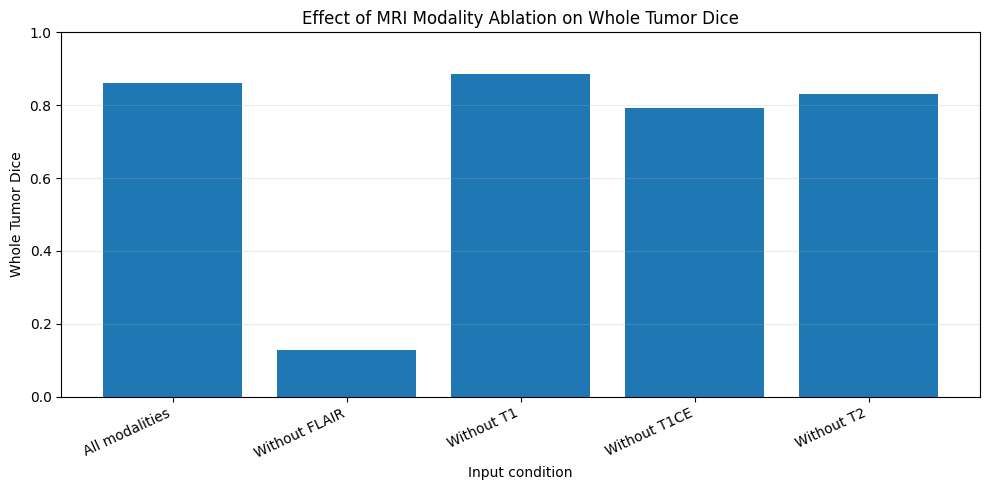

Saved: /kaggle/working/brain_tumor_3d_artifacts/modality_ablation_dice.png


In [33]:
# Plot modality ablation results

plot_df = ablation_df.copy()

plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["condition"],
    plot_df["WT_Dice_Mean"]
)

plt.ylabel("Whole Tumor Dice")
plt.xlabel("Input condition")
plt.title(
    "Effect of MRI Modality Ablation on Whole Tumor Dice"
)

plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

ablation_plot_path = os.path.join(
    ARTIFACT_DIR,
    "modality_ablation_dice.png"
)

plt.savefig(
    ablation_plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", ablation_plot_path)

## 24. Prediction Uncertainty Estimation

The segmentation model produces a probability distribution across the four classes for every voxel.

Prediction uncertainty can be estimated using normalized predictive entropy:

Entropy = -Σ p(c) log p(c)

The entropy is normalized by log(number of classes), producing a value approximately between 0 and 1.

- Low entropy → the model is relatively confident.
- High entropy → the model is less certain between classes.

This is an exploratory uncertainty visualization and should not be interpreted as a calibrated clinical confidence measure.

In [34]:
# Calculate normalized voxel-wise prediction entropy

def prediction_entropy(probabilities):
    """
    Calculate normalized entropy from class probabilities.

    Input:
        probabilities: (..., NUM_CLASSES)

    Output:
        normalized entropy: (...)
    """

    probabilities = np.asarray(
        probabilities,
        dtype=np.float32
    )

    probabilities = np.clip(
        probabilities,
        1e-8,
        1.0
    )

    entropy = -np.sum(
        probabilities * np.log(probabilities),
        axis=-1
    )

    max_entropy = np.log(
        probabilities.shape[-1]
    )

    return entropy / max_entropy


# test_probs was generated during Cell 20.
test_uncertainty = prediction_entropy(
    test_probs
)

print(
    "Uncertainty shape:",
    test_uncertainty.shape
)

print(
    "Minimum:",
    float(test_uncertainty.min())
)

print(
    "Maximum:",
    float(test_uncertainty.max())
)

print(
    "Mean:",
    float(test_uncertainty.mean())
)

# Uncertainty specifically inside ground-truth tumor.
tumor_region = test_gt > 0

if tumor_region.any():
    tumor_uncertainty = test_uncertainty[
        tumor_region
    ]

    print(
        "Mean tumor-region uncertainty:",
        float(tumor_uncertainty.mean())
    )
else:
    print(
        "No tumor voxels found in this test volume."
    )

Uncertainty shape: (240, 240, 155)
Minimum: 0.004311837166528555
Maximum: 0.9970418151616696
Mean: 0.05253734136075567
Mean tumor-region uncertainty: 0.2659573173984828


In [35]:
# Prepare uncertainty visualization

uncertainty_z = int(
    np.argmax(
        (test_gt > 0).sum(axis=(0, 1))
    )
)

uncertainty_slice = test_uncertainty[
    :, :,
    uncertainty_z
]

prediction_slice = test_pred[
    :, :,
    uncertainty_z
]

flair_slice = test_image[
    :, :,
    uncertainty_z,
    0
]

print(
    "Selected uncertainty slice:",
    uncertainty_z
)

print(
    "Mean uncertainty on slice:",
    float(
        uncertainty_slice.mean()
    )
)

print(
    "Mean uncertainty inside tumor on slice:",
    float(
        uncertainty_slice[
            test_gt[:, :, uncertainty_z] > 0
        ].mean()
    )
    if np.any(
        test_gt[:, :, uncertainty_z] > 0
    )
    else "No tumor"
)

Selected uncertainty slice: 66
Mean uncertainty on slice: 0.0604662195370433
Mean uncertainty inside tumor on slice: 0.24812842777750466


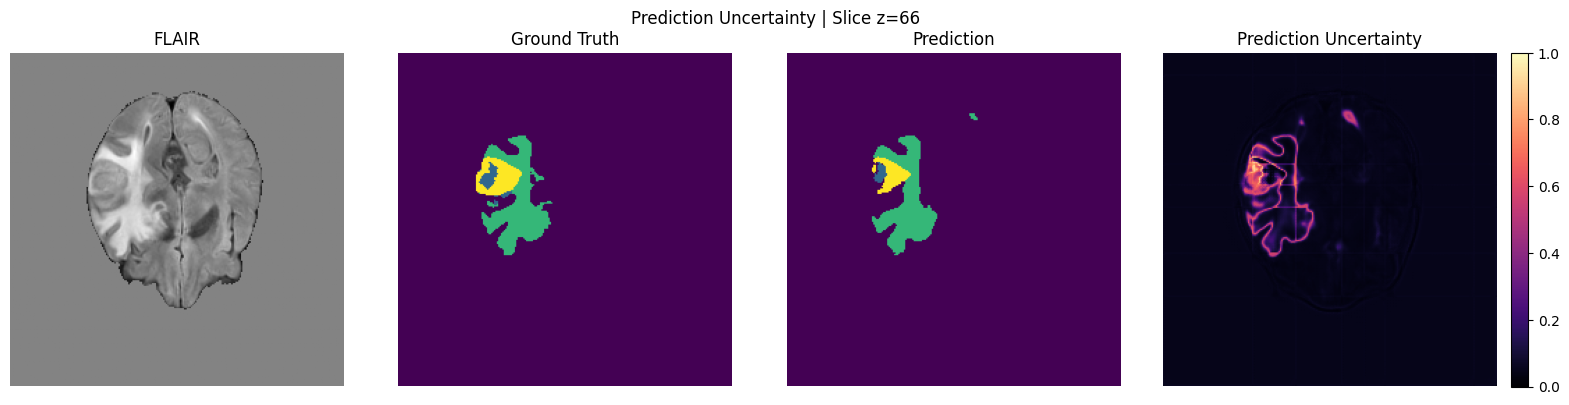

Saved: /kaggle/working/brain_tumor_3d_artifacts/prediction_uncertainty.png


In [36]:
# Visualize prediction uncertainty

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4)
)

axes[0].imshow(
    flair_slice.T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title("FLAIR")

axes[1].imshow(
    test_gt[:, :, uncertainty_z].T,
    cmap="viridis",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[1].set_title("Ground Truth")

axes[2].imshow(
    prediction_slice.T,
    cmap="viridis",
    vmin=0,
    vmax=3,
    origin="lower"
)
axes[2].set_title("Prediction")

uncertainty_image = axes[3].imshow(
    uncertainty_slice.T,
    cmap="magma",
    vmin=0,
    vmax=1,
    origin="lower"
)

axes[3].set_title("Prediction Uncertainty")

plt.colorbar(
    uncertainty_image,
    ax=axes[3],
    fraction=0.046,
    pad=0.04
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Prediction Uncertainty | Slice z={uncertainty_z}"
)

plt.tight_layout()

uncertainty_path = os.path.join(
    ARTIFACT_DIR,
    "prediction_uncertainty.png"
)

plt.savefig(
    uncertainty_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", uncertainty_path)

## 25. Comparison with the Previous 2D Attention CNN + ViT

The previous project used a 2D Attention CNN + Vision Transformer architecture.

Its reported Whole Tumor Dice was:

- 89.37% on selected tumor-enriched test slices.

The current model is a 3D U-Net evaluated on complete 3D test volumes:

- 82.98% Whole Tumor Dice across 56 held-out patients.

These values must not be interpreted as a direct head-to-head comparison because the evaluation protocols are different.

The previous evaluation used selected slices, whereas the current evaluation reconstructs and evaluates complete 3D patient volumes.

The comparison is therefore presented as a protocol-aware project comparison rather than a claim that one architecture is superior.

In [37]:
# Protocol-aware comparison with the previous project

comparison_df = pd.DataFrame([
    {
        "Model": "Previous 2D Attention CNN + ViT",
        "Input / Evaluation": "Selected tumor-enriched slices",
        "Test Patients": 56,
        "Whole Tumor Dice": 0.8937,
        "Whole Tumor IoU": 0.8078
    },
    {
        "Model": "Current 3D U-Net",
        "Input / Evaluation": "Complete 3D volumes",
        "Test Patients": 56,
        "Whole Tumor Dice": 0.829760,
        "Whole Tumor IoU": 0.728292
    }
])

print("=== PROTOCOL-AWARE MODEL COMPARISON ===")

display(
    comparison_df.style.format({
        "Whole Tumor Dice": "{:.2%}",
        "Whole Tumor IoU": "{:.2%}"
    })
)

comparison_csv = os.path.join(
    ARTIFACT_DIR,
    "model_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv,
    index=False
)

print("Saved:", comparison_csv)

=== PROTOCOL-AWARE MODEL COMPARISON ===


,Model,Input / Evaluation,Test Patients,Whole Tumor Dice,Whole Tumor IoU
0,Previous 2D Attention CNN + ViT,Selected tumor-enriched slices,56,89.37%,80.78%
1,Current 3D U-Net,Complete 3D volumes,56,82.98%,72.83%


Saved: /kaggle/working/brain_tumor_3d_artifacts/model_comparison.csv


## 26. Final Results Summary

The final results summarize the complete-volume evaluation of the trained 3D U-Net.

The primary headline metric is Whole Tumor Dice because it measures overlap between the predicted tumor region and the ground-truth tumor region while combining the three tumor sub-regions.

Pixel accuracy is reported separately because the large background region can make pixel accuracy very high even when tumor segmentation performance is substantially lower.

The final model should be described as an experimental research baseline and not as a clinically validated diagnostic system.

In [38]:
# Final verified 3D U-Net results

final_metrics_df = pd.DataFrame([
    ("Whole Tumor Dice", 0.829760),
    ("Whole Tumor IoU", 0.728292),
    ("Tumor Core Dice", 0.696069),
    ("Tumor Core IoU", 0.593072),
    ("Necrotic Dice", 0.470383),
    ("Necrotic IoU", 0.360244),
    ("Edema Dice", 0.694502),
    ("Edema IoU", 0.572507),
    ("Enhancing Dice", 0.641072),
    ("Enhancing IoU", 0.544092),
    ("Mean Foreground Dice", 0.601986),
    ("Mean Foreground IoU", 0.492281),
    ("Pixel Accuracy", 0.995746)
], columns=[
    "Metric",
    "Score"
])

print("=== FINAL 3D U-NET TEST RESULTS ===")

display(
    final_metrics_df.style.format({
        "Score": "{:.2%}"
    })
)

print("\nPrimary headline:")
print(
    f"Whole Tumor Dice = "
    f"{0.829760:.2%}"
)

print(
    "\nEvaluation protocol: "
    "complete-volume test evaluation"
)

print(
    "Held-out test patients: 56"
)

print(
    "Model parameters:",
    best_model.count_params()
)

=== FINAL 3D U-NET TEST RESULTS ===


,Metric,Score
0,Whole Tumor Dice,82.98%
1,Whole Tumor IoU,72.83%
2,Tumor Core Dice,69.61%
3,Tumor Core IoU,59.31%
4,Necrotic Dice,47.04%
5,Necrotic IoU,36.02%
6,Edema Dice,69.45%
7,Edema IoU,57.25%
8,Enhancing Dice,64.11%
9,Enhancing IoU,54.41%



Primary headline:
Whole Tumor Dice = 82.98%

Evaluation protocol: complete-volume test evaluation
Held-out test patients: 56
Model parameters: 5606628


In [39]:
# Save final project artifacts

# Final metrics
final_metrics_path = os.path.join(
    ARTIFACT_DIR,
    "final_3d_unet_test_metrics.csv"
)

final_metrics_df.to_csv(
    final_metrics_path,
    index=False
)


# Training history
if "history" in globals():

    history_df = pd.DataFrame(
        history.history
    )

    history_path = os.path.join(
        ARTIFACT_DIR,
        "3d_unet_training_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print("Saved:", history_path)


# Save uncertainty statistics
uncertainty_summary = pd.DataFrame([
    {
        "overall_mean_entropy": float(
            test_uncertainty.mean()
        ),
        "overall_max_entropy": float(
            test_uncertainty.max()
        ),
        "tumor_mean_entropy": (
            float(
                test_uncertainty[
                    test_gt > 0
                ].mean()
            )
            if np.any(test_gt > 0)
            else np.nan
        )
    }
])

uncertainty_csv = os.path.join(
    ARTIFACT_DIR,
    "uncertainty_summary.csv"
)

uncertainty_summary.to_csv(
    uncertainty_csv,
    index=False
)


# Save Grad-CAM arrays
for class_index, heatmap in gradcam_maps.items():

    np.save(
        os.path.join(
            ARTIFACT_DIR,
            f"gradcam_class_{class_index}.npy"
        ),
        heatmap
    )


# Save the final comparison table
comparison_df.to_csv(
    comparison_csv,
    index=False
)


print("\n=== SAVED ARTIFACTS ===")

for file_name in sorted(
    os.listdir(ARTIFACT_DIR)
):
    print(file_name)

print(
    "\nArtifact directory:",
    ARTIFACT_DIR
)

Saved: /kaggle/working/brain_tumor_3d_artifacts/3d_unet_training_history.csv

=== SAVED ARTIFACTS ===
3d_gradcam_visualization.png
3d_unet_complete_volume_test_metrics.csv
3d_unet_training_history.csv
best_3d_unet_model.keras
bottleneck_feature_visualization.png
final_3d_unet_test_metrics.csv
gradcam_class_1.npy
gradcam_class_2.npy
gradcam_class_3.npy
modality_ablation_dice.png
modality_ablation_results.csv
modality_ablation_visualization.png
model_comparison.csv
prediction_uncertainty.png
uncertainty_summary.csv

Artifact directory: /kaggle/working/brain_tumor_3d_artifacts


## 27. Final Project Conclusion

This project developed an explainable 3D U-Net baseline for multi-class brain tumor segmentation using multimodal BraTS2020 MRI.

The model uses four MRI modalities:

- FLAIR
- T1
- T1CE
- T2

Unlike the previous 2D approach, the 3D U-Net processes volumetric patches and therefore incorporates spatial information across neighboring MRI slices.

The model was trained using patient-level train, validation, and test separation and evaluated on 56 held-out patients using complete-volume sliding-window inference.

The final complete-volume test result was:

**Whole Tumor Dice: 82.98%**

Additional analysis included:

- Class-specific segmentation metrics
- 3D Grad-CAM visualization
- Bottleneck feature visualization
- MRI modality ablation
- Prediction uncertainty estimation
- Protocol-aware comparison with the previous 2D Attention CNN + ViT

The class-specific results show that segmentation of the smaller tumor sub-regions remains more difficult than whole-tumor segmentation, particularly for the necrotic/non-enhancing region.

The results demonstrate a functional research-oriented 3D segmentation and explainability pipeline. However, the model has not undergone external validation or clinical validation and should not be considered a clinical diagnostic system.

Future work can investigate stronger 3D architectures, Transformer-based volumetric models, improved class-imbalance handling, uncertainty calibration, external validation, and clinically relevant downstream analysis.